# Forecasting next-year revenue of Ukrainian companies

We forecast the net revenue of every Ukrainian company one year ahead from its annual financial statements. The notebook only reads the prepared panel `panel_v1.parquet` and shows the whole pipeline: data, EDA, the validation scheme, six models and the decision.

# 0. Goal and data

**Target.** Net revenue (line 2000) of company *i* in year *t+1*, thousand UAH, in real 2021 prices (deflated with the annual average CPI of Derzhstat). Models work on the scale $z = \log(1 + y)$ and go back with `expm1`.

**Population.** Companies with $y_t > 0$ that filed a report both for *t* and for *t+1*. Rows with anomaly flags stay in the data; metrics are computed on all rows and on the clean part (rows without flags).

**Horizon.** $h = 1$ year. The data is annual, so there is no seasonality and no seasonal naive model.

**Data.** data.gov.ua, "Financial statements of enterprises (annual)", files for 2021-2024. Duplicates of EDRPOU + year keep the latest filing. The 2025 file is the holdout and is never downloaded or read. The heavy part (parsing XML, line codes, CPI, deduplication) lives in a separate pipeline; here we read only the published panel.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

REQUIRED_MODULES = ['polars', 'lightgbm', 'statsmodels', 'sklearn', 'huggingface_hub', 'matplotlib']
if any(importlib.util.find_spec(name) is None for name in REQUIRED_MODULES):
    requirements = Path('requirements.txt')
    targets = ['-r', str(requirements)] if requirements.exists() else [
        'polars==2.1.0', 'lightgbm==4.7.0', 'statsmodels==0.15.0', 'scikit-learn==1.9.1',
        'huggingface_hub==2.4.0', 'matplotlib==3.11.2',
    ]
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *targets])

In [2]:
from dataclasses import dataclass
from typing import Callable, Iterable

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import statsmodels.api as sm
from IPython.display import display
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

INK, INK_2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8986', '#e6e5e0'
BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#6250d6', '#e34948'
FOLD_COLORS = {'F1': '#86b6ef', 'F2': '#1c5cab'}
MODEL_COLORS = {'N1': INK_2, 'N2': MUTED, 'N3': '#bdbcb6', 'M1': VIOLET, 'M2': AQUA, 'M3': ORANGE}

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2,
})
pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(4)

polars.config.Config

In [3]:
ROOT = Path('/content') if Path('/content').exists() else Path('.')
OUT = ROOT / 'out'
OUT.mkdir(parents=True, exist_ok=True)
HF_REPO = 'Shnnapka/fin-zvit-ua'
PANEL_NAME = 'panel_v1.parquet'

local_panel = OUT / PANEL_NAME
if not local_panel.exists():
    from huggingface_hub import hf_hub_download
    panel = pl.read_parquet(hf_hub_download(HF_REPO, f'panel/{PANEL_NAME}', repo_type='dataset', token=False))
    panel.write_parquet(local_panel)
else:
    panel = pl.read_parquet(local_panel)

required = {'edrpou', 't', 'target_year', 'z_t', 'z_lag', 'z_next', 'dz_next',
            'flag_units_x1000', 'flag_balance_mismatch', 'flag_extreme_growth',
            'flag_zero_revenue', 'has_anomaly'}
assert not required.difference(panel.columns), 'panel_v1.parquet has an outdated schema'
assert panel['target_year'].max() == 2024 and panel['target_year'].min() == 2022
f1_lag_missing = panel.filter(pl.col('target_year') == 2022)['z_lag'].is_null().mean()
assert f1_lag_missing < 0.20, 'Outdated panel: F1 still has no 2020 lag'

print(f'panel: {panel.height:,} rows, companies: {panel["edrpou"].n_unique():,}')
display(panel.group_by('target_year').agg(
    pl.len().alias('rows'),
    pl.col('z_lag').is_null().mean().alias('share_lag_missing'),
).sort('target_year'))

panel: 602,041 rows, companies: 267,960


target_year,rows,share_lag_missing
i64,u32,f64
2022,155689,0.0805
2023,219622,0.0557
2024,226730,0.0832


**Result.** The panel has 602,041 rows for 267,960 companies. The lag $z_{t-1}$ is missing in 8.05% of rows for target year 2022, 5.57% for 2023 and 8.32% for 2024. The 2020 lag comes from the "previous year" column of the 2021 report and is brought to 2021 prices by dividing by 1.10; other years use the annual average CPI. The version check stops the notebook if somebody runs it on an old panel with an empty F1 lag.

# 1. EDA and preprocessing

target_year,micro,small,full
i64,u32,u32,u32
2022,44409,99852,11428
2023,65840,140660,13122
2024,71642,142422,12666


target_year,median_y_t,median_z_t,median_dz_next,share_z_next_zero
i64,f64,f64,f64,f64
2022,3769.8000,8.2350,-0.4667,0.0593
2023,1649.6256,7.4089,0.0409,0.0721
2024,1898.9977,7.5496,0.0374,0.0578


flag_units_x1000,flag_balance_mismatch,flag_extreme_growth,flag_zero_revenue,has_anomaly
f64,f64,f64,f64,f64
0.0004,0.0001,0.0584,0.0000,0.0589


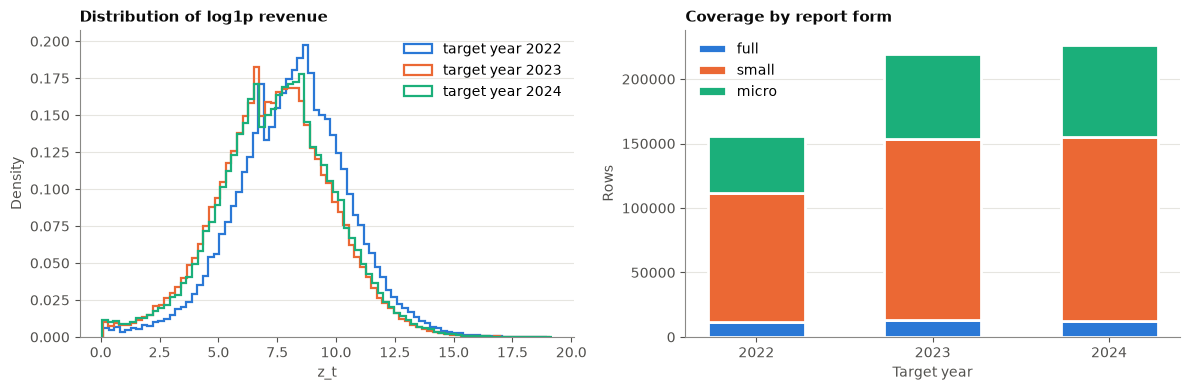

In [4]:
FLAG_COLUMNS = ['flag_units_x1000', 'flag_balance_mismatch', 'flag_extreme_growth', 'flag_zero_revenue']
FORM_ORDER = ['full', 'small', 'micro']
YEAR_COLORS = {2022: BLUE, 2023: ORANGE, 2024: AQUA}

coverage = (panel.group_by('target_year', 'form').len()
            .pivot(on='form', index='target_year', values='len').sort('target_year'))
revenue_summary = panel.group_by('target_year').agg(
    pl.col('y_t').median().alias('median_y_t'),
    pl.col('z_t').median().alias('median_z_t'),
    pl.col('dz_next').median().alias('median_dz_next'),
    (pl.col('z_next') == 0).mean().alias('share_z_next_zero'),
).sort('target_year')
flag_summary = panel.select(
    *[pl.col(c).mean().alias(c) for c in FLAG_COLUMNS],
    pl.col('has_anomaly').mean().alias('has_anomaly'),
)
display(coverage)
display(revenue_summary)
display(flag_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for year in panel['target_year'].unique().sort().to_list():
    values = panel.filter(pl.col('target_year') == year)['z_t'].to_numpy()
    axes[0].hist(values, bins=80, density=True, histtype='step', linewidth=1.6,
                 color=YEAR_COLORS[year], label=f'target year {year}')
axes[0].set(title='Distribution of log1p revenue', xlabel='z_t', ylabel='Density')
axes[0].legend()
years = coverage['target_year'].to_numpy()
bottom = np.zeros(len(years))
for form, color in zip(FORM_ORDER, [BLUE, ORANGE, AQUA]):
    values = coverage[form].fill_null(0).to_numpy()
    axes[1].bar(years.astype(str), values, bottom=bottom, label=form, color=color,
                width=0.55, edgecolor='white', linewidth=2)
    bottom += values
axes[1].set(title='Coverage by report form', xlabel='Target year', ylabel='Rows')
axes[1].legend()
plt.tight_layout()
plt.show()

**Result.** Revenue has a long right tail, so all models are evaluated on the `log1p` scale. The data is annual, so seasonality inside a year cannot be observed. `flag_units_x1000` is used only for EDA and the clean evaluation, because it needs the repeated value from the report for *t+1*. `flag_zero_revenue` is a constant after the population filter $y_t > 0$. Both flags are excluded from the model features.

# 2. Validation

This section is the backbone of the project. It fixes four things that every model has to share: the folds, the metrics, the features and the harness that runs a model and returns one row of the summary table. Everything here was first written on synthetic data and then switched to the real panel without code changes.

## 2.1 Folds: expanding-window backtest

| Fold | Train (target year) | Test (target year) |
|---|---|---|
| F1 | 2022 | 2023 |
| F2 | 2022-2023 | 2024 |
| Holdout | 2022-2024 | 2025, not opened |

Features for target year *t+1* come only from reports for years $\le t$. Every next fold adds one year to the training part, which is an **expanding window**. The alternative is a **rolling window**, where the training part has a fixed length (for example, only the last year). We use expanding as the official scheme because the panel covers only four report years and every training year is valuable. Rolling is used only as a sensitivity check in section 4.

The horizon is $h = 1$: one row is (company, year *t*), the features are from *t*, the target is revenue in *t+1*.

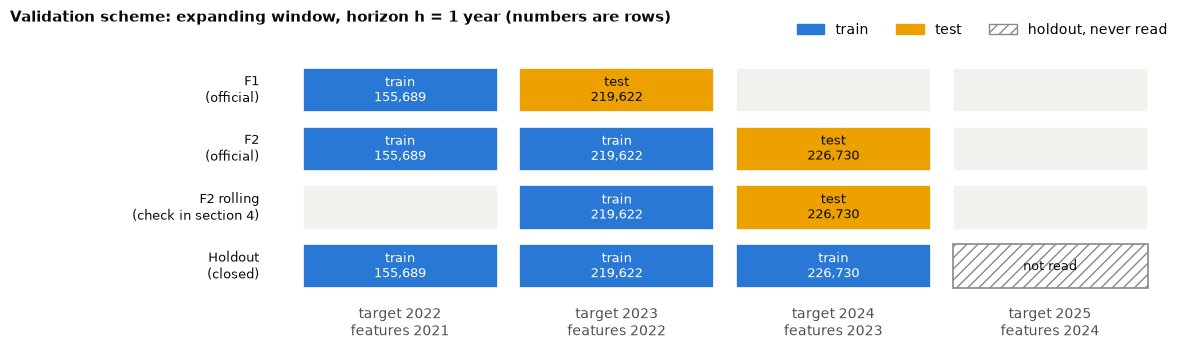

In [5]:
FOLDS = {'F1': ([2022], 2023), 'F2': ([2022, 2023], 2024)}
HOLDOUT_YEAR = 2025


def split_fold(data: pl.DataFrame, train_years: list[int], test_year: int) -> tuple[pl.DataFrame, pl.DataFrame]:
    train = data.filter(pl.col('target_year').is_in(train_years))
    test = data.filter(pl.col('target_year') == test_year)
    assert train['target_year'].max() < test_year
    assert test['target_year'].max() < HOLDOUT_YEAR
    return train, test


rows_by_year = dict(panel.group_by('target_year').len().iter_rows())
scheme = [
    ('F1', [2022], 2023, 'official'),
    ('F2', [2022, 2023], 2024, 'official'),
    ('F2 rolling', [2023], 2024, 'check in section 4'),
    ('Holdout', [2022, 2023, 2024], 2025, 'closed'),
]
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.grid(False)
for row, (name, train_years, test_year, role) in enumerate(scheme):
    y = len(scheme) - 1 - row
    for year in range(2022, 2026):
        if year in train_years:
            color, label, hatch = BLUE, f'train\n{rows_by_year.get(year, 0):,}', None
        elif year == test_year and name != 'Holdout':
            color, label, hatch = YELLOW, f'test\n{rows_by_year.get(year, 0):,}', None
        elif year == test_year:
            color, label, hatch = 'white', 'not read', '///'
        else:
            color, label, hatch = '#f2f1ee', '', None
        ax.add_patch(Rectangle((year - 0.45, y - 0.38), 0.9, 0.76, facecolor=color, edgecolor=MUTED if hatch else 'white',
                               hatch=hatch, linewidth=1.2))
        ax.text(year, y, label, ha='center', va='center', fontsize=9,
                color='white' if color == BLUE else INK)
    ax.text(2021.35, y, f'{name}\n({role})', ha='right', va='center', fontsize=9.5, color=INK)
ax.set(xlim=(2020.2, 2025.6), ylim=(-0.6, len(scheme) - 0.4), yticks=[])
ax.set_xticks(range(2022, 2026), [f'target {y}\nfeatures {y - 1}' for y in range(2022, 2026)])
ax.spines[['left', 'bottom']].set_visible(False)
ax.tick_params(length=0)
ax.legend(handles=[Patch(color=BLUE, label='train'), Patch(color=YELLOW, label='test'),
                   Patch(facecolor='white', edgecolor=MUTED, hatch='///', label='holdout, never read')],
          loc='upper right', bbox_to_anchor=(1.0, 1.18), ncol=3)
ax.set_title('Validation scheme: expanding window, horizon h = 1 year (numbers are rows)', pad=24)
plt.tight_layout()
plt.show()

## 2.2 Metrics

| Metric | Formula | Why |
|---|---|---|
| **MAE_log** (main) | $\text{mean}\,|z - \hat z|$ | robust, scale free, every company counts the same |
| Skill | $1 - \text{MAE}_{\log}(\text{model}) / \text{MAE}_{\log}(\text{N1})$ | replaces MASE, which cannot be scaled on series of 2-4 points |
| Bias | $\text{mean}(\hat z - z)$ | above zero means the forecast is too high |
| MdAPE | $\text{median}\,|y - \hat y| / y$, only $y > 0$ | typical relative error in money |
| WAPE | $\sum |y - \hat y| / \sum y$ | error weighted by size, dominated by large companies |

We do not use MAPE (explodes on small denominators) and RMSE in levels (decided by a few giants). The main number is the mean MAE_log over F1 and F2.

In [6]:
METRICS = ['MAE_log', 'Skill', 'Bias', 'MdAPE', 'WAPE']


def regression_metrics(z: Iterable[float], z_hat: Iterable[float], z_n1: Iterable[float]) -> dict[str, float]:
    z = np.asarray(z, dtype=float)
    z_hat = np.asarray(z_hat, dtype=float)
    z_n1 = np.asarray(z_n1, dtype=float)
    y = np.expm1(np.clip(z, -50, 50))
    y_hat = np.expm1(np.clip(z_hat, -50, 50))
    positive = y > 0
    mae = float(np.mean(np.abs(z - z_hat)))
    n1_mae = float(np.mean(np.abs(z - z_n1)))
    return {
        'MAE_log': mae,
        'Skill': 1 - mae / n1_mae if n1_mae else np.nan,
        'Bias': float(np.mean(z_hat - z)),
        'MdAPE': float(np.median(np.abs(y[positive] - y_hat[positive]) / y[positive])) if positive.any() else np.nan,
        'WAPE': float(np.sum(np.abs(y - y_hat)) / np.sum(y)) if np.sum(y) else np.nan,
        'n': int(len(z)),
    }


toy = regression_metrics([1.0, 2.0, 3.0], [1.5, 2.0, 2.0], [1.0, 1.0, 1.0])
assert np.isclose(toy['MAE_log'], 0.5) and np.isclose(toy['Skill'], 0.5) and np.isclose(toy['Bias'], -1 / 6)

## 2.3 Features

Only indicators that exist in all three report forms (full, small, micro). Every feature is computed from the report for year *t* (and the "previous year" column of that report for the lag).

| Feature | Formula |
|---|---|
| `z_t` | log1p(line 2000) |
| `z_lag`, `lag_missing` | $z_{t-1}$, missing value plus a flag |
| `dz_t` | $z_t - z_{t-1}$ |
| `log_assets` | log1p(line 1300) |
| `asinh_equity` | asinh(line 1495) |
| `leverage` | (line 1595 + line 1695) / line 1300, clipped to [0, 5]; an empty liability line counts as zero |
| `asset_turnover` | line 2000 / line 1300, clipped at the train 99th percentile (fitted inside the model) |
| `sales_margin` | net result / line 2000, clipped to [-1, 1] |
| `sector_growth` | median `dz_t` in the KVED section in year *t*, country median if the section is unknown |
| `log_employees` | log1p(employees) |
| `flag_balance_mismatch`, `flag_extreme_growth` | anomaly flags from the report for *t* |
| `form`, `kved_section`, `obl` | categories |

`flag_units_x1000` is deliberately not a feature: it compares report *t* with the repeated value in report *t+1*, so it uses the future.

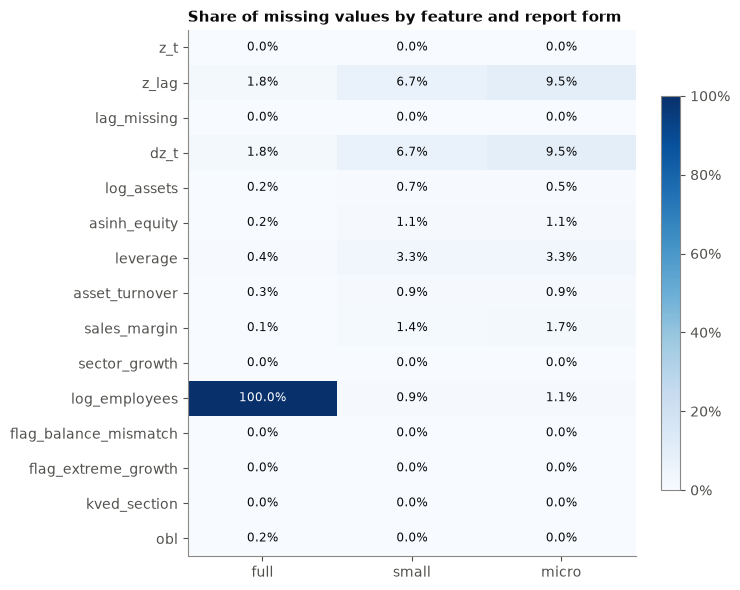

In [7]:
NUMERIC_FEATURES = [
    'z_t', 'z_lag', 'lag_missing', 'dz_t', 'log_assets', 'asinh_equity', 'leverage',
    'asset_turnover', 'sales_margin', 'sector_growth', 'log_employees',
    'flag_balance_mismatch', 'flag_extreme_growth',
]
CATEGORICAL_FEATURES = ['form', 'kved_section', 'obl']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET_COLUMNS = {'y_next', 'z_next', 'dz_next', 'form_next', 'target_year'}
FUTURE_DERIVED_FEATURES = {'flag_units_x1000'}
EDA_ONLY_FLAGS = {'flag_units_x1000', 'flag_zero_revenue'}


def build_features(panel: pl.DataFrame) -> pl.DataFrame:
    growth = panel.with_columns((pl.col('z_t') - pl.col('z_lag')).alias('dz_t'))
    observed = growth.filter(pl.col('dz_t').is_not_null())
    by_sector = observed.group_by('t', 'kved_section').agg(pl.col('dz_t').median().alias('_sector_growth'))
    by_country = observed.group_by('t').agg(pl.col('dz_t').median().alias('_country_growth'))
    return (
        growth.join(by_sector, on=['t', 'kved_section'], how='left')
        .join(by_country, on='t', how='left')
        .with_columns(
            pl.col('z_lag').is_null().cast(pl.Int8).alias('lag_missing'),
            pl.when(pl.col('assets') >= 0).then(pl.col('assets').log1p()).alias('log_assets'),
            pl.col('equity').arcsinh().alias('asinh_equity'),
            pl.when((pl.col('assets') > 0) & (pl.col('lt_liab').is_not_null() | pl.col('cur_liab').is_not_null()))
            .then(((pl.col('lt_liab').fill_null(0) + pl.col('cur_liab').fill_null(0)) / pl.col('assets')).clip(0, 5))
            .alias('leverage'),
            pl.when(pl.col('assets') > 0).then(pl.col('y_t') / pl.col('assets')).alias('asset_turnover'),
            (pl.col('net_result') / pl.col('y_t')).clip(-1, 1).alias('sales_margin'),
            pl.coalesce('_sector_growth', '_country_growth').alias('sector_growth'),
            pl.when(pl.col('employees') >= 0).then(pl.col('employees').log1p()).alias('log_employees'),
        )
        .drop('_sector_growth', '_country_growth')
    )


data = build_features(panel)
assert data.height == panel.height

missing = data.group_by('form').agg(
    *[pl.col(c).is_null().mean().alias(c) for c in NUMERIC_FEATURES + ['kved_section', 'obl']]
)
missing = missing.sort(pl.col('form').replace_strict({f: i for i, f in enumerate(FORM_ORDER)}, default=9))
names = [c for c in missing.columns if c != 'form']
matrix = missing.select(names).to_numpy().T

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.grid(False)
image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(0.3, matrix.max()), aspect='auto')
ax.set_xticks(range(missing.height), missing['form'].to_list())
ax.set_yticks(range(len(names)), names)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, f'{matrix[i, j]:.1%}', ha='center', va='center', fontsize=8.5,
                color='white' if matrix[i, j] > 0.6 * max(0.3, matrix.max()) else INK)
ax.set_title('Share of missing values by feature and report form')
fig.colorbar(image, ax=ax, fraction=0.04, format=PercentFormatter(1.0))
plt.tight_layout()
plt.show()

**Result.** The financial features are almost complete in all forms, so a model can use them for every company. Most missing values come from the lag (new companies). Two findings from this chart: the panel has **no employee count for the full form at all**, which is a gap in the data pipeline; and an empty long-term liability line in small and micro forms means zero (the balance closes exactly), so `leverage` treats it as zero instead of a missing value. Missing values are not dropped: M2 fills them with train medians plus missing indicators, M3 handles them natively.

## 2.4 Harness

Every model is an object with two methods: `fit(train)` and `predict(test)`, where `predict` returns $\hat z_{t+1}$. The harness runs a list of models through both folds, evaluates every model on the same rows for the populations `all` and `clean`, and returns one long table `model x fold x population x metric`. Skill is always computed against N1 on the same rows. Because all six models go through one function, they cannot differ in folds, rows or metric code.

In [8]:
PREDICTION_KEYS = ['edrpou', 't', 'target_year', 'form', 'kved_section', 'has_anomaly', 'z_t', 'z_next', 'y_next']


@dataclass
class RuleModel:
    rule: Callable[[pl.DataFrame], np.ndarray]

    def fit(self, train: pl.DataFrame) -> 'RuleModel':
        return self

    def predict(self, test: pl.DataFrame) -> np.ndarray:
        return np.asarray(self.rule(test), dtype=float)


def run_harness(factories: dict, data: pl.DataFrame, folds: dict = FOLDS):
    rows, frames, fitted = [], [], {}
    for fold, (train_years, test_year) in folds.items():
        train, test = split_fold(data, train_years, test_year)
        pred = test.select(PREDICTION_KEYS).with_columns(pl.lit(fold).alias('fold'))
        for name, make in factories.items():
            model = make().fit(train)
            z_hat = model.predict(test)
            assert z_hat.shape == (test.height,) and np.isfinite(z_hat).all(), f'{name} {fold}: bad forecast'
            pred = pred.with_columns(pl.Series(name, z_hat))
            fitted[name, fold] = model
        for population, subset in (('all', pred), ('clean', pred.filter(~pl.col('has_anomaly')))):
            for name in factories:
                rows.append({'model': name, 'fold': fold, 'population': population,
                             **regression_metrics(subset['z_next'], subset[name], subset['z_t'])})
        frames.append(pred)
    return pl.DataFrame(rows), pl.concat(frames, how='vertical_relaxed'), fitted


def make_synthetic_panel(n_companies: int = 2000, seed: int = 0) -> pl.DataFrame:
    rng = np.random.default_rng(seed)
    year_shift = {2021: -0.5, 2022: 0.1, 2023: 0.05}
    level = rng.normal(8, 2, n_companies)
    rows = []
    for t, shift in year_shift.items():
        z_next = level + shift + rng.normal(0, 0.3, n_companies)
        rows.append(pl.DataFrame({
            'edrpou': [f'{i:08d}' for i in range(n_companies)], 't': t, 'target_year': t + 1,
            'form': rng.choice(FORM_ORDER, n_companies), 'kved_section': rng.choice(list('ACG'), n_companies),
            'has_anomaly': rng.random(n_companies) < 0.1, 'z_t': level, 'z_next': z_next,
            'y_next': np.expm1(z_next),
        }))
        level = z_next
    return pl.concat(rows)


synthetic = make_synthetic_panel()
synthetic_results, _, _ = run_harness({
    'N1': lambda: RuleModel(lambda d: d['z_t'].to_numpy()),
    'oracle': lambda: RuleModel(lambda d: d['z_next'].to_numpy()),
    'plus_one': lambda: RuleModel(lambda d: d['z_t'].to_numpy() + 1),
}, synthetic)
check = synthetic_results.filter(pl.col('population') == 'all')
assert check.filter(pl.col('model') == 'N1')['Skill'].abs().max() < 1e-12
assert check.filter(pl.col('model') == 'oracle')['MAE_log'].max() < 1e-12
assert (check.filter(pl.col('model') == 'oracle')['Skill'] == 1).all()
assert (check.filter(pl.col('model') == 'plus_one')['Skill'] < 0).all()
assert synthetic_results.height == 3 * len(FOLDS) * 2
print('Harness passes the synthetic checks: N1 Skill = 0, oracle MAE = 0, a shifted forecast loses to N1.')
display(check.select('model', 'fold', 'MAE_log', 'Skill', 'Bias', 'n'))

Harness passes the synthetic checks: N1 Skill = 0, oracle MAE = 0, a shifted forecast loses to N1.


model,fold,MAE_log,Skill,Bias,n
str,str,f64,f64,f64,i64
"""N1""","""F1""",0.2555,0.0000,-0.1121,2000
"""oracle""","""F1""",0.0000,1.0000,0.0000,2000
"""plus_one""","""F1""",0.8881,-2.4760,0.8879,2000
"""N1""","""F2""",0.2416,0.0000,-0.0567,2000
"""oracle""","""F2""",0.0000,1.0000,0.0000,2000
"""plus_one""","""F2""",0.9434,-2.9046,0.9433,2000


## 2.5 Leakage checks

The four checks from the specification. Check 2 (preprocessing is fitted on the training part only) needs fitted models, so it runs right after the harness in section 3.2.

1. The feature year is smaller than the target year in every row, and the features do not change if the targets are scrambled or if future years are removed.
2. Scalers, medians for missing values, the turnover cap and category maps are fitted on the training part of a fold only.
3. There is no "present in all years" filter: companies that appear only once stay in the panel.
4. The 2025 file is never read.

In [9]:
scrambled = panel.with_columns(*[pl.col(c).shuffle(seed=0) for c in ['y_next', 'z_next', 'dz_next', 'form_next']])
only_past = panel.filter(pl.col('target_year') <= 2023)
features_from_past = build_features(only_past).filter(pl.col('target_year') == 2023).sort('edrpou')
features_full = data.filter(pl.col('target_year') == 2023).sort('edrpou')
companies_per_count = panel.group_by('edrpou').len()['len']
f2_train, f2_test = split_fold(data, *FOLDS['F2'])
new_in_test = f2_test.join(f2_train.select('edrpou').unique(), on='edrpou', how='anti').height

leakage_checks = {
    '1. t < target year in every row': bool((panel['t'] < panel['target_year']).all()),
    '1. horizon is exactly one year': bool(((panel['target_year'] - panel['t']) == 1).all()),
    '1. no target or future column among features': not set(FEATURES) & (TARGET_COLUMNS | FUTURE_DERIVED_FEATURES | EDA_ONLY_FLAGS),
    '1. features unchanged when targets are scrambled': build_features(scrambled).select(FEATURES).equals(data.select(FEATURES)),
    '1. features for 2023 unchanged without later years': features_from_past.select(FEATURES).equals(features_full.select(FEATURES)),
    '3. companies seen in only one year are kept': bool((companies_per_count == 1).any()),
    '3. F2 test has companies unseen in train': new_in_test > 0,
    '4. no target year 2025 or later': panel['target_year'].max() < HOLDOUT_YEAR,
    '4. no report year 2024 or later as features': panel['t'].max() < HOLDOUT_YEAR - 1,
    '4. only the panel file is read': PANEL_NAME == 'panel_v1.parquet',
}
display(pl.DataFrame({'check': list(leakage_checks), 'passed': list(leakage_checks.values())}))
assert all(leakage_checks.values()), 'leakage check failed'

check,passed
str,bool
"""1. t < target year in every ro…",true
"""1. horizon is exactly one year""",true
"""1. no target or future column …",true
"""1. features unchanged when tar…",true
"""1. features for 2023 unchanged…",true
"""3. companies seen in only one …",true
"""3. F2 test has companies unsee…",true
"""4. no target year 2025 or late…",true
"""4. no report year 2024 or late…",true


# 3. Baselines

## 3.1 Models

| Code | Forecast $\hat z_{t+1}$ |
|---|---|
| N1 Persistence | $z_t$, the reference for Skill |
| N2 Sector drift | $z_t$ + median $\Delta z_t$ in the KVED section (country median without KVED) |
| N3 Two-year mean | $(z_t + z_{t-1}) / 2$, or $z_t$ without a lag |
| M1 Panel AR(1) | OLS $z_{t+1} = \alpha + \beta z_t$; $\beta < 1$ means mean reversion |
| M2 Ridge | target $\Delta z_{t+1}$, train medians and scaling, one-hot categories, alpha = 1 |
| M3 LightGBM | target $\Delta z_{t+1}$, L1 loss, early stopping on 10% of train companies |

M3 uses `objective = regression_l1`, `num_leaves = 63`, `learning_rate = 0.05`, up to 2000 trees with early stopping after 50 rounds, `min_child_samples = 100`, `feature_fraction = bagging_fraction = 0.8`, categorical `form` and `kved_section`, `seed = 42`. The early stopping validation is a random 10% of EDRPOU codes from the training part of the fold; after it, the model is refitted on the whole training part with the best number of trees. Missing values go to LightGBM as they are, so "no lag" is a signal, not a median.

In [10]:
def naive_n1(d: pl.DataFrame) -> np.ndarray:
    return d['z_t'].to_numpy()


def naive_n2(d: pl.DataFrame) -> np.ndarray:
    return (d['z_t'] + d['sector_growth'].fill_null(0.0)).to_numpy()


def naive_n3(d: pl.DataFrame) -> np.ndarray:
    return d.select(pl.when(pl.col('z_lag').is_not_null())
                    .then((pl.col('z_t') + pl.col('z_lag')) / 2)
                    .otherwise(pl.col('z_t')).alias('n3'))['n3'].to_numpy()


class PanelAR1:
    def fit(self, train: pl.DataFrame) -> 'PanelAR1':
        self.ols_ = sm.OLS(train['z_next'].to_numpy(), sm.add_constant(train['z_t'].to_numpy())).fit()
        return self

    def predict(self, test: pl.DataFrame) -> np.ndarray:
        return self.ols_.predict(sm.add_constant(test['z_t'].to_numpy(), has_constant='add'))


def fit_turnover_cap(train: pl.DataFrame) -> float:
    finite = train.filter(pl.col('asset_turnover').is_finite())['asset_turnover']
    return float(finite.quantile(0.99)) if len(finite) else 0.0


def cap_turnover(data: pl.DataFrame, cap: float) -> pl.DataFrame:
    return data.with_columns(pl.col('asset_turnover').clip(upper_bound=cap))


class RidgeDeltaModel:
    def __init__(self, alpha: float = 1.0):
        self.alpha = alpha

    def fit(self, train: pl.DataFrame) -> 'RidgeDeltaModel':
        self.turnover_cap_ = fit_turnover_cap(train)
        train = cap_turnover(train, self.turnover_cap_)
        n_num = len(NUMERIC_FEATURES)
        numeric = Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
            ('scaler', StandardScaler()),
        ])
        categorical = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ])
        self.pipeline_ = Pipeline([
            ('preprocess', ColumnTransformer([
                ('numeric', numeric, list(range(n_num))),
                ('categorical', categorical, list(range(n_num, len(FEATURES)))),
            ])),
            ('ridge', Ridge(alpha=self.alpha)),
        ])
        self.pipeline_.fit(train.select(FEATURES).to_numpy(), train['dz_next'].to_numpy())
        return self

    def predict(self, test: pl.DataFrame) -> np.ndarray:
        test = cap_turnover(test, self.turnover_cap_)
        return test['z_t'].to_numpy() + self.pipeline_.predict(test.select(FEATURES).to_numpy())

In [11]:
M3_CATEGORICAL = ['form', 'kved_section']
M3_FEATURES = NUMERIC_FEATURES + M3_CATEGORICAL


class LightGBMDeltaModel:
    def __init__(self, seed: int = 42, max_rounds: int = 2000, patience: int = 50, valid_share: int = 10):
        self.seed, self.max_rounds, self.patience, self.valid_share = seed, max_rounds, patience, valid_share

    def params(self) -> dict:
        return {
            'objective': 'regression_l1', 'metric': 'l1', 'num_leaves': 63, 'learning_rate': 0.05,
            'min_child_samples': 100, 'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 1,
            'seed': self.seed, 'deterministic': True, 'num_threads': 0, 'verbosity': -1,
        }

    def _fit_encoding(self, train: pl.DataFrame) -> None:
        self.turnover_cap_ = fit_turnover_cap(train)
        self.category_maps_ = {
            column: {value: code for code, value in enumerate(sorted(train[column].drop_nulls().unique().to_list()))}
            for column in M3_CATEGORICAL
        }

    def _matrix(self, data: pl.DataFrame) -> np.ndarray:
        data = cap_turnover(data, self.turnover_cap_).with_columns(
            *[pl.col(c).replace_strict(self.category_maps_[c], default=None, return_dtype=pl.Float64)
              for c in M3_CATEGORICAL]
        )
        matrix = data.select(M3_FEATURES).cast(pl.Float64).to_numpy()
        matrix[~np.isfinite(matrix)] = np.nan
        return matrix

    def _dataset(self, data: pl.DataFrame, reference=None) -> lgb.Dataset:
        return lgb.Dataset(self._matrix(data), label=data['dz_next'].to_numpy(), feature_name=M3_FEATURES,
                           categorical_feature=M3_CATEGORICAL, reference=reference, free_raw_data=False)

    def fit(self, train: pl.DataFrame) -> 'LightGBMDeltaModel':
        is_valid = train['edrpou'].hash(seed=self.seed) % self.valid_share == 0
        inner_fit, inner_valid = train.filter(~is_valid), train.filter(is_valid)
        assert inner_fit.join(inner_valid, on='edrpou', how='semi').is_empty()
        self._fit_encoding(inner_fit)
        fit_set = self._dataset(inner_fit)
        valid_set = self._dataset(inner_valid, reference=fit_set)
        self.curve_ = {}
        early = lgb.train(self.params(), fit_set, num_boost_round=self.max_rounds,
                          valid_sets=[valid_set], valid_names=['inner_valid'],
                          callbacks=[lgb.early_stopping(self.patience, verbose=False),
                                     lgb.record_evaluation(self.curve_)])
        self.best_iteration_ = max(1, early.best_iteration)
        self.inner_n1_mae_ = float(inner_valid['dz_next'].abs().mean())

        self._fit_encoding(train)
        self.booster_ = lgb.train(self.params(), self._dataset(train), num_boost_round=self.best_iteration_)
        return self

    def predict(self, test: pl.DataFrame) -> np.ndarray:
        return test['z_t'].to_numpy() + self.booster_.predict(self._matrix(test))

## 3.2 Results: six models through one harness

In [12]:
MODELS = ['N1', 'N2', 'N3', 'M1', 'M2', 'M3']
FACTORIES = {
    'N1': lambda: RuleModel(naive_n1),
    'N2': lambda: RuleModel(naive_n2),
    'N3': lambda: RuleModel(naive_n3),
    'M1': PanelAR1,
    'M2': lambda: RidgeDeltaModel(alpha=1.0),
    'M3': lambda: LightGBMDeltaModel(seed=42),
}
results, predictions, fitted = run_harness(FACTORIES, data)

display(results.filter(pl.col('population') == 'all')
        .select('model', 'fold', *METRICS, 'n')
        .sort(pl.col('model').replace_strict({m: i for i, m in enumerate(MODELS)}), 'fold'))
print('M1 coefficients (alpha, beta):', {fold: np.round(fitted['M1', fold].ols_.params, 4).tolist() for fold in FOLDS})
print('M3 best number of trees:', {fold: fitted['M3', fold].best_iteration_ for fold in FOLDS})

results.write_parquet(OUT / 'comparison_six_models.parquet')
predictions.write_parquet(OUT / 'predictions_six_models.parquet')

model,fold,MAE_log,Skill,Bias,MdAPE,WAPE,n
str,str,f64,f64,f64,f64,f64,i64
"""N1""","""F1""",1.0263,0.0000,0.2765,0.3469,0.3773,219622
"""N1""","""F2""",0.9049,0.0000,0.2180,0.2973,0.3798,226730
"""N2""","""F1""",1.1536,-0.1241,-0.1175,0.4719,0.4834,219622
"""N2""","""F2""",0.9159,-0.0121,0.3370,0.3170,0.3986,226730
"""N3""","""F1""",1.1346,-0.1056,0.4660,0.3875,0.4482,219622
"""N3""","""F2""",1.0385,-0.1477,0.1006,0.3663,0.4453,226730
"""M1""","""F1""",1.4334,-0.3968,-0.5684,0.6484,0.7146,219622
"""M1""","""F2""",1.1308,-0.2497,-0.2958,0.5040,0.6470,226730
"""M2""","""F1""",1.5189,-0.4801,-0.7435,0.6961,0.7110,219622


M1 coefficients (alpha, beta): {'F1': [-0.6345, 0.9715], 'F2': [-0.2471, 0.9644]}
M3 best number of trees: {'F1': 697, 'F2': 1310}


**Leakage check 2.** Every statistic used for preprocessing must equal the same statistic recomputed on the training part of that fold.

In [13]:
preprocessing_checks = []
for fold, (train_years, test_year) in FOLDS.items():
    train, test = split_fold(data, train_years, test_year)

    m2 = fitted['M2', fold]
    numeric = m2.pipeline_.named_steps['preprocess'].named_transformers_['numeric']
    imputer, scaler = numeric.named_steps['imputer'], numeric.named_steps['scaler']
    x_train = cap_turnover(train, m2.turnover_cap_).select(NUMERIC_FEATURES).cast(pl.Float64).to_numpy()
    observed = ~np.isnan(x_train).all(axis=0)
    preprocessing_checks += [
        (fold, 'M2 turnover cap = train 99th percentile', np.isclose(m2.turnover_cap_, fit_turnover_cap(train))),
        (fold, 'M2 imputer medians = train medians',
         np.allclose(imputer.statistics_[observed], np.nanmedian(x_train[:, observed], axis=0))),
        (fold, 'M2 scaler means = train means', np.allclose(scaler.mean_, imputer.transform(x_train).mean(axis=0))),
    ]

    m3 = fitted['M3', fold]
    preprocessing_checks += [
        (fold, 'M3 turnover cap = train 99th percentile', np.isclose(m3.turnover_cap_, fit_turnover_cap(train))),
        (fold, 'M3 category codes come from train only',
         all(set(m3.category_maps_[c]) == set(train[c].drop_nulls().unique().to_list()) for c in M3_CATEGORICAL)),
    ]
    preprocessing_checks.append((fold, 'test statistics would differ (check is not trivial)',
                                 not np.isclose(fit_turnover_cap(train), fit_turnover_cap(pl.concat([train, test])))))

checks = pl.DataFrame({'fold': [f for f, _, _ in preprocessing_checks],
                       'check': [c for _, c, _ in preprocessing_checks],
                       'passed': [bool(p) for _, _, p in preprocessing_checks]})
display(checks)
assert checks['passed'].all(), 'preprocessing leaks test information'

fold,check,passed
str,str,bool
"""F1""","""M2 turnover cap = train 99th p…",true
"""F1""","""M2 imputer medians = train med…",true
"""F1""","""M2 scaler means = train means""",true
"""F1""","""M3 turnover cap = train 99th p…",true
"""F1""","""M3 category codes come from tr…",true
"""F1""","""test statistics would differ (…",true
"""F2""","""M2 turnover cap = train 99th p…",true
"""F2""","""M2 imputer medians = train med…",true
"""F2""","""M2 scaler means = train means""",true


## 3.3 Summary table and decision rule

A model **works** if Skill > 0 in both F1 and F2. The **best** model has the smallest mean MAE_log over F1 and F2.

In [14]:
def decision_table(results: pl.DataFrame, population: str) -> pl.DataFrame:
    wide = results.filter(pl.col('population') == population).pivot(
        on='fold', index='model', values=['MAE_log', 'Skill', 'Bias'])
    table = wide.with_columns(
        pl.mean_horizontal('MAE_log_F1', 'MAE_log_F2').alias('mean_MAE_log'),
        ((pl.col('Skill_F1') > 0) & (pl.col('Skill_F2') > 0)).alias('works'),
    ).sort('mean_MAE_log')
    return table.with_columns((pl.col('model') == table['model'][0]).alias('best')).select(
        'model', 'MAE_log_F1', 'MAE_log_F2', 'mean_MAE_log', 'Skill_F1', 'Skill_F2', 'Bias_F1', 'Bias_F2', 'works', 'best')


decision = decision_table(results, 'all')
decision_clean = decision_table(results, 'clean')
best_model = decision['model'][0]
working = decision.filter(pl.col('works'))['model'].to_list()
display(decision)
print(f'Best model by mean MAE_log: {best_model}')
print(f'Working models (Skill > 0 in F1 and F2): {working or "none"}')
print(f'Best on the clean population: {decision_clean["model"][0]}')

model,MAE_log_F1,MAE_log_F2,mean_MAE_log,Skill_F1,Skill_F2,Bias_F1,Bias_F2,works,best
str,f64,f64,f64,f64,f64,f64,f64,bool,bool
"""N1""",1.0263,0.9049,0.9656,0.0000,0.0000,0.2765,0.2180,false,true
"""N2""",1.1536,0.9159,1.0348,-0.1241,-0.0121,-0.1175,0.3370,false,false
"""N3""",1.1346,1.0385,1.0866,-0.1056,-0.1477,0.4660,0.1006,false,false
"""M3""",1.2429,1.0632,1.1531,-0.2111,-0.1749,-0.4071,-0.2848,false,false
"""M1""",1.4334,1.1308,1.2821,-0.3968,-0.2497,-0.5684,-0.2958,false,false
"""M2""",1.5189,1.3198,1.4194,-0.4801,-0.4585,-0.7435,-0.6239,false,false


Best model by mean MAE_log: N1
Working models (Skill > 0 in F1 and F2): none
Best on the clean population: N1


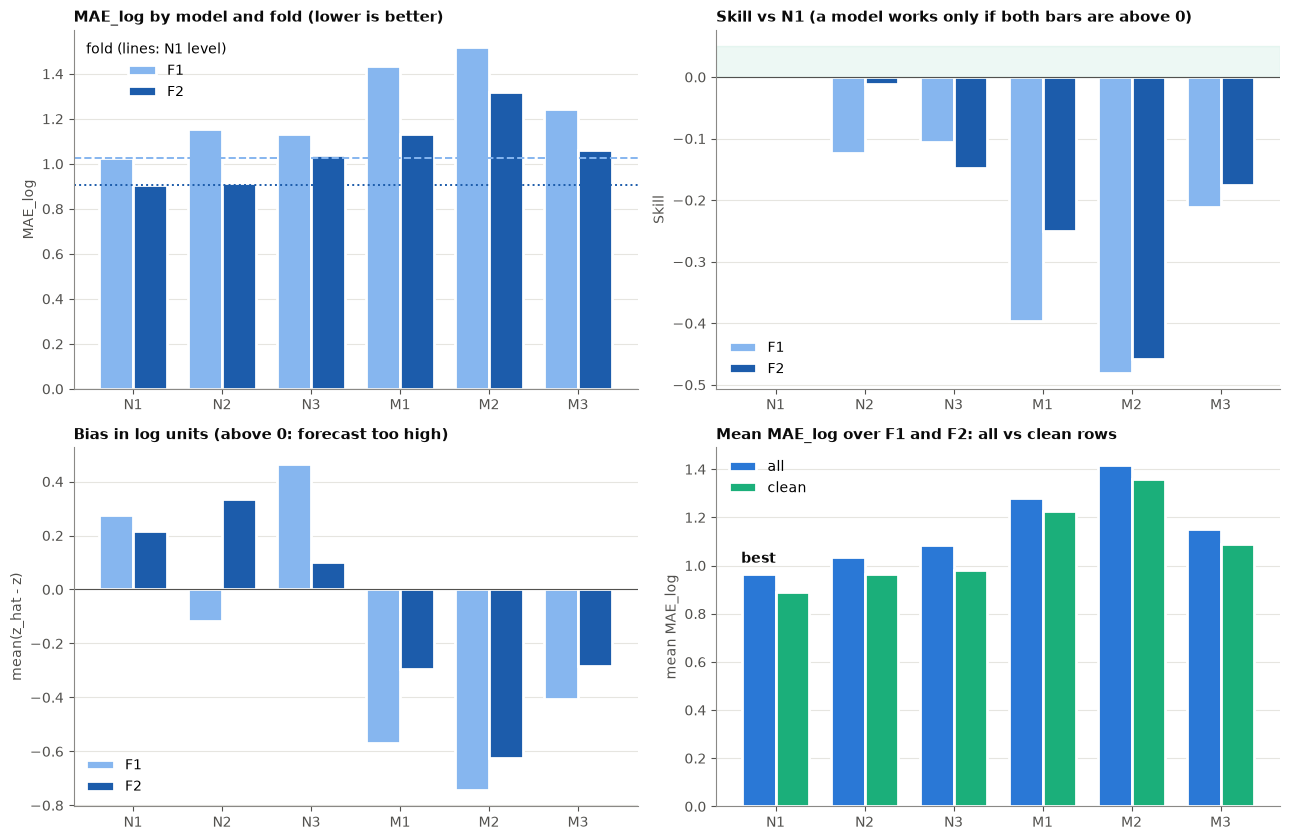

In [15]:
def model_bars(ax, metric: str, population: str = 'all', title: str = '') -> None:
    frame = results.filter(pl.col('population') == population)
    x = np.arange(len(MODELS))
    for k, fold in enumerate(FOLDS):
        values = [frame.filter((pl.col('model') == m) & (pl.col('fold') == fold))[metric][0] for m in MODELS]
        ax.bar(x + (k - 0.5) * 0.38, values, width=0.38, color=FOLD_COLORS[fold], label=fold,
               edgecolor='white', linewidth=2)
    ax.set_xticks(x, MODELS)
    ax.set_title(title)
    ax.axhline(0, color=INK_2, linewidth=0.8)


fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
model_bars(axes[0, 0], 'MAE_log', title='MAE_log by model and fold (lower is better)')
for fold, style in zip(FOLDS, ['--', ':']):
    n1 = results.filter((pl.col('model') == 'N1') & (pl.col('fold') == fold) & (pl.col('population') == 'all'))['MAE_log'][0]
    axes[0, 0].axhline(n1, color=FOLD_COLORS[fold], linestyle=style, linewidth=1.4)
axes[0, 0].set_ylabel('MAE_log')
axes[0, 0].legend(title='fold (lines: N1 level)', loc='upper left')

model_bars(axes[0, 1], 'Skill', title='Skill vs N1 (a model works only if both bars are above 0)')
axes[0, 1].axhspan(0, axes[0, 1].get_ylim()[1] if axes[0, 1].get_ylim()[1] > 0 else 0.05, color=AQUA, alpha=0.08)
axes[0, 1].set_ylabel('Skill')
axes[0, 1].legend(loc='lower left')

model_bars(axes[1, 0], 'Bias', title='Bias in log units (above 0: forecast too high)')
axes[1, 0].set_ylabel('mean(z_hat - z)')
axes[1, 0].legend(loc='lower left')

x = np.arange(len(MODELS))
for k, (population, color) in enumerate([('all', BLUE), ('clean', AQUA)]):
    table = decision if population == 'all' else decision_clean
    values = [table.filter(pl.col('model') == m)['mean_MAE_log'][0] for m in MODELS]
    axes[1, 1].bar(x + (k - 0.5) * 0.38, values, width=0.38, color=color, label=population,
                   edgecolor='white', linewidth=2)
axes[1, 1].set_xticks(x, MODELS)
axes[1, 1].set_title('Mean MAE_log over F1 and F2: all vs clean rows')
axes[1, 1].set_ylabel('mean MAE_log')
axes[1, 1].legend(loc='upper left')
best_x = MODELS.index(best_model)
axes[1, 1].annotate('best', (best_x - 0.19, decision['mean_MAE_log'][0]), xytext=(0, 8),
                    textcoords='offset points', ha='center', color=INK, fontweight='bold')
plt.tight_layout()
plt.show()

**Result.** As the four charts show, no trained model beats persistence. N1 has the lowest mean MAE_log (0.966 on all rows, 0.892 on clean rows), and every other model has negative Skill in both folds. By the rule no model "works", so **N1 stays the final model**. The ranking is the same on clean rows, so the result is not driven by anomaly flags.

The bias chart gives the main hint. N1 is slightly too high (the median company lost a little real revenue), while M1, M2 and M3 are clearly too low in both folds: the trained models are pessimistic. M1 has $\beta$ just below 1 (0.97 in F1, 0.96 in F2), which is mild mean reversion, but its intercept is learned on the shock year and pulls every forecast down. Section 3.4 shows the same effect inside M3.

## 3.4 M3 deep dive: what the booster learned and why it loses

Three questions: did early stopping work, which features matter, and why a model that learns well inside the training years still loses to persistence on the next year.

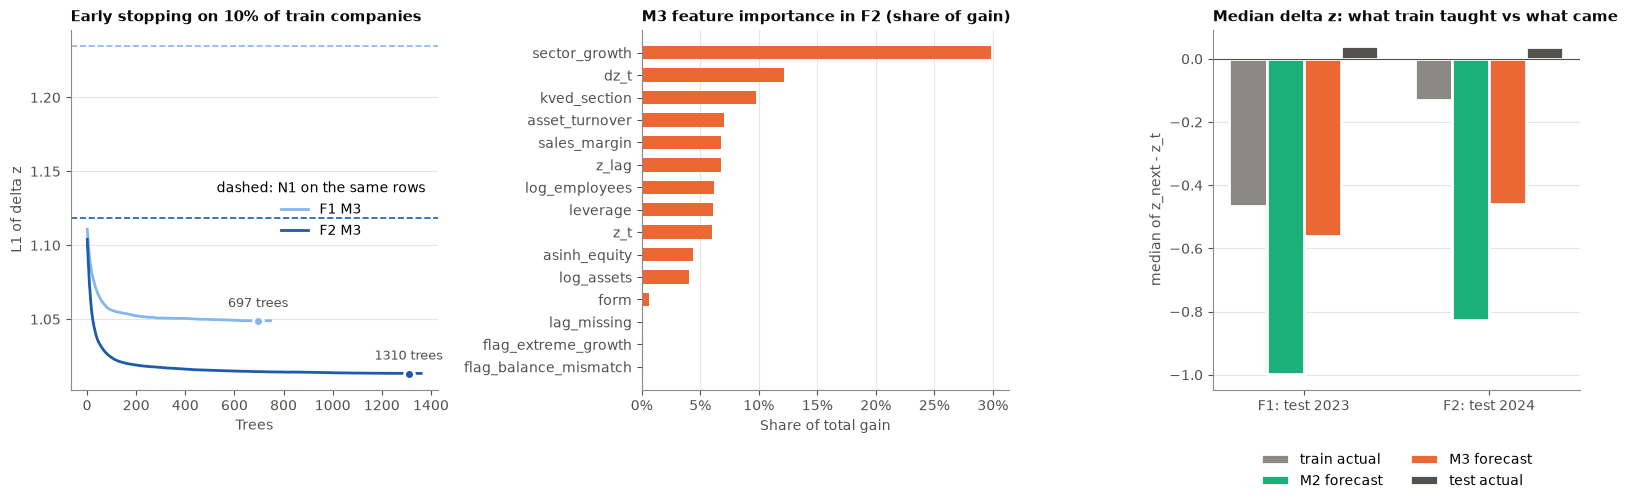

fold,train actual,M2 forecast,M3 forecast,test actual
str,f64,f64,f64,f64
"""F1""",-0.4667,-0.9960,-0.5616,0.0409
"""F2""",-0.1308,-0.8256,-0.4604,0.0374


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for fold in FOLDS:
    model = fitted['M3', fold]
    curve = model.curve_['inner_valid']['l1']
    axes[0].plot(np.arange(1, len(curve) + 1), curve, color=FOLD_COLORS[fold], label=f'{fold} M3')
    axes[0].axhline(model.inner_n1_mae_, color=FOLD_COLORS[fold], linestyle='--', linewidth=1.2)
    axes[0].scatter([model.best_iteration_], [curve[model.best_iteration_ - 1]], s=50, color=FOLD_COLORS[fold],
                    edgecolor='white', linewidth=2, zorder=3)
    axes[0].annotate(f'{model.best_iteration_} trees', (model.best_iteration_, curve[model.best_iteration_ - 1]),
                     xytext=(0, 10), textcoords='offset points', ha='center', fontsize=9, color=INK_2)
axes[0].set(title='Early stopping on 10% of train companies', xlabel='Trees', ylabel='L1 of delta z')
axes[0].legend(title='dashed: N1 on the same rows', loc='center right')

booster = fitted['M3', 'F2'].booster_
gain = booster.feature_importance(importance_type='gain')
order = np.argsort(gain)
axes[1].barh(np.array(M3_FEATURES)[order], gain[order] / gain.sum(), color=ORANGE, height=0.6)
axes[1].grid(axis='x', color=GRID)
axes[1].grid(axis='y', visible=False)
axes[1].set(title='M3 feature importance in F2 (share of gain)', xlabel='Share of total gain')
axes[1].xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')

shift_rows = []
for fold, (train_years, test_year) in FOLDS.items():
    train, _ = split_fold(data, train_years, test_year)
    fold_pred = predictions.filter(pl.col('fold') == fold)
    shift_rows.append({
        'fold': fold,
        'train actual': train['dz_next'].median(),
        'M2 forecast': (fold_pred['M2'] - fold_pred['z_t']).median(),
        'M3 forecast': (fold_pred['M3'] - fold_pred['z_t']).median(),
        'test actual': (fold_pred['z_next'] - fold_pred['z_t']).median(),
    })
shift = pl.DataFrame(shift_rows)
series = [('train actual', MUTED), ('M2 forecast', AQUA), ('M3 forecast', ORANGE), ('test actual', INK_2)]
x = np.arange(shift.height)
for k, (name, color) in enumerate(series):
    axes[2].bar(x + (k - 1.5) * 0.2, shift[name], width=0.2, color=color, label=name, edgecolor='white', linewidth=2)
axes[2].axhline(0, color=INK_2, linewidth=0.8)
axes[2].set_xticks(x, [f'{f}: test {FOLDS[f][1]}' for f in shift['fold']])
axes[2].set(title='Median delta z: what train taught vs what came', ylabel='median of z_next - z_t')
axes[2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2)
plt.tight_layout()
plt.show()
display(shift)

**Result.** Early stopping works: inside the training years M3 clearly beats N1 on companies it has never seen (the solid lines are well below the dashed ones). It stops at 697 trees in F1 and 1310 in F2; this number jumps a lot after small changes in the data, so it is not a stable property of the model.

The most important feature is `sector_growth`, followed by `dz_t` and the KVED section, so the booster mostly learns "what happened to the sector this year". The right chart explains the failure on the test years. Target year 2022 is the war shock with a median drop of about 0.47 in log units, while in 2023 and 2024 the median company was flat. M3 carries the shock into the future and forecasts a median drop of about 0.5. M2 is even more pessimistic, because a squared loss also chases companies whose revenue falls to zero. So the problem is not overfitting to companies but a change of regime between years, which two folds cannot teach.

## 3.5 Segments for the best model

MAE_log and Bias of the best model by report form and KVED section, both folds together. Segments with fewer than 500 rows are hidden on the chart but stay in the table.

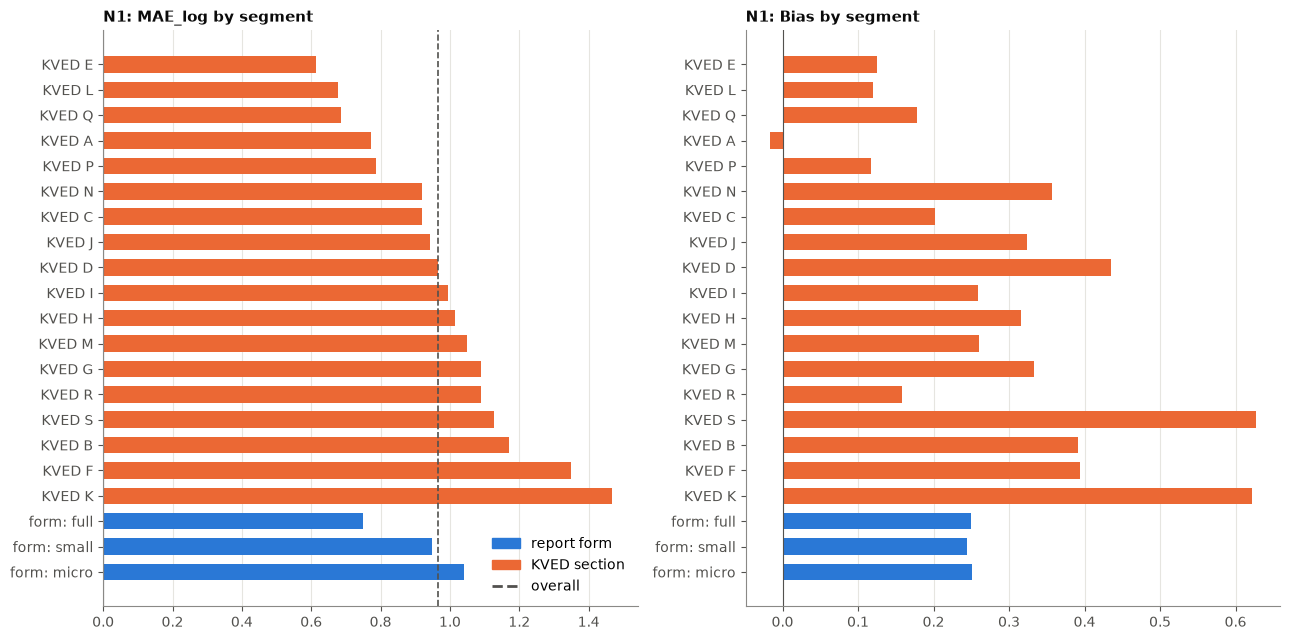

model,segment,segment_value,MAE_log,Bias,n
str,str,str,f64,f64,u32
"""N1""","""form""","""full""",0.7486,0.2500,25788
"""N1""","""form""","""small""",0.9471,0.2441,283082
"""N1""","""form""","""micro""",1.0412,0.2516,137482
"""N1""","""kved_section""","""E""",0.6139,0.1257,4411
"""N1""","""kved_section""","""O""",0.6720,0.1510,434
"""N1""","""kved_section""","""L""",0.6765,0.1193,46554
"""N1""","""kved_section""","""Q""",0.6863,0.1779,11676
"""N1""","""kved_section""","""A""",0.7711,-0.0166,56714
"""N1""","""kved_section""","""P""",0.7878,0.1173,4998


In [17]:
def segment_metrics(predictions: pl.DataFrame, prediction_column: str,
                    segments: Iterable[str] = ('form', 'kved_section')) -> pl.DataFrame:
    frames = []
    for segment in segments:
        frames.append(
            predictions.group_by(segment).agg(
                (pl.col(prediction_column) - pl.col('z_next')).abs().mean().alias('MAE_log'),
                (pl.col(prediction_column) - pl.col('z_next')).mean().alias('Bias'),
                pl.len().alias('n'),
            ).rename({segment: 'segment_value'}).with_columns(
                pl.col('segment_value').cast(pl.String),
                pl.lit(segment).alias('segment'),
                pl.lit(prediction_column).alias('model'),
            )
        )
    return pl.concat(frames, how='diagonal_relaxed').select('model', 'segment', 'segment_value', 'MAE_log', 'Bias', 'n')


segments = segment_metrics(predictions, best_model)
segments.write_parquet(OUT / 'segments.parquet')

shown = segments.filter(pl.col('n') >= 500).sort('segment', 'MAE_log', descending=[False, True])
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={'width_ratios': [1, 1]})
labels = [f'{s}: {v}' if s == 'form' else f'KVED {v}' for s, v in zip(shown['segment'], shown['segment_value'])]
colors = [BLUE if s == 'form' else ORANGE for s in shown['segment']]
for ax, metric, title in [(axes[0], 'MAE_log', f'{best_model}: MAE_log by segment'),
                          (axes[1], 'Bias', f'{best_model}: Bias by segment')]:
    ax.barh(labels, shown[metric], color=colors, height=0.65)
    ax.grid(axis='x', color=GRID)
    ax.grid(axis='y', visible=False)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.set_title(title)
axes[0].axvline(segments.filter(pl.col('segment') == 'form')
                .select((pl.col('MAE_log') * pl.col('n')).sum() / pl.col('n').sum()).item(),
                color=INK_2, linestyle='--', linewidth=1.2)
axes[0].legend(handles=[Patch(color=BLUE, label='report form'), Patch(color=ORANGE, label='KVED section'),
                        plt.Line2D([], [], color=INK_2, linestyle='--', label='overall')], loc='lower right')
plt.tight_layout()
plt.show()
display(segments.sort('segment', 'MAE_log'))

**Result.** For N1 the error grows from the full form to small and micro: smaller companies have more volatile revenue. By sector, utilities (E), real estate (L) and health care (Q) are the most stable, construction (F) and finance (K) are the hardest. Bias is positive in almost every segment, so persistence overestimates next year's revenue nearly everywhere, most of all in S and K. Sections T and U have only 3 and 2 rows and are not interpreted.

# 4. Bridge to optimization

## 4.1 Diagnostics: random GroupKFold and rolling window

GroupKFold by EDRPOU inside the F2 training years shows how optimistic a random split would be. The rolling window trains F2 only on target year 2023, without the shock year 2022. Both are checks, not the official evaluation.

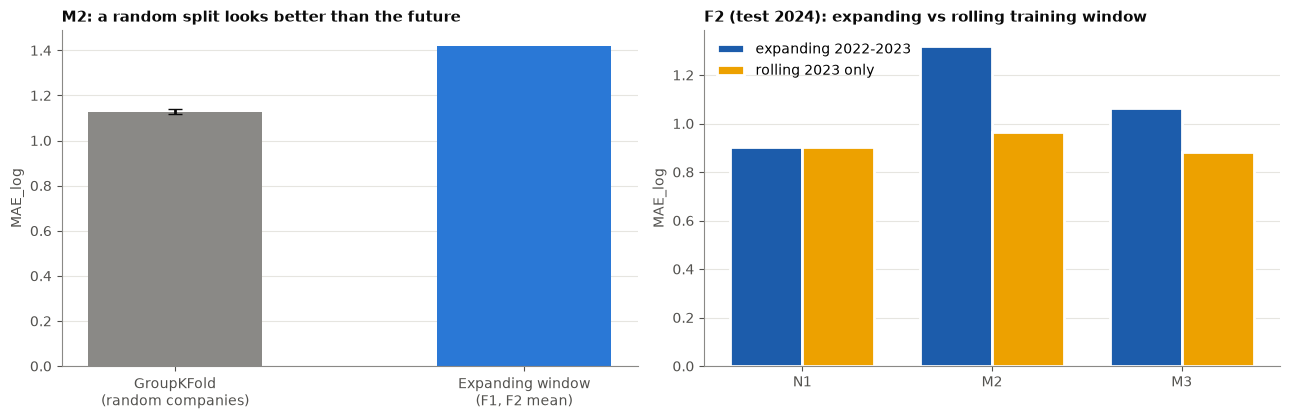

GroupKFold_MAE_log_mean,GroupKFold_MAE_log_sd
f64,f64
1.1279,0.0121


model,fold,MAE_log,Skill,Bias,MdAPE,WAPE,n
str,str,f64,f64,f64,f64,f64,i64
"""N1""","""F2 rolling""",0.9049,0.0000,0.2180,0.2973,0.3798,226730
"""M2""","""F2 rolling""",0.9648,-0.0662,0.0872,0.3960,0.5462,226730
"""M3""","""F2 rolling""",0.8821,0.0252,0.2529,0.3036,0.3711,226730


In [18]:
def group_cv(train: pl.DataFrame, factory: Callable, n_splits: int = 5) -> pl.DataFrame:
    rows = []
    splitter = GroupKFold(n_splits=n_splits)
    for cv_fold, (fit_idx, val_idx) in enumerate(splitter.split(np.zeros(train.height), groups=train['edrpou'].to_numpy()), 1):
        fit, val = train[fit_idx], train[val_idx]
        z_hat = factory().fit(fit).predict(val)
        rows.append({'cv_fold': cv_fold, **regression_metrics(val['z_next'], z_hat, val['z_t'])})
    return pl.DataFrame(rows)


cv_source = split_fold(data, *FOLDS['F2'])[0].filter(pl.col('edrpou').hash(seed=42) % 10 == 0)
cv_results = group_cv(cv_source, FACTORIES['M2'])
cv_results.write_parquet(OUT / 'cv_m2.parquet')

rolling_results, rolling_predictions, _ = run_harness(
    {name: FACTORIES[name] for name in ['N1', 'M2', 'M3']}, data, folds={'F2 rolling': ([2023], 2024)})
rolling_results = rolling_results.filter(pl.col('population') == 'all')
rolling_results.write_parquet(OUT / 'rolling_window.parquet')

f2_all = results.filter((pl.col('fold') == 'F2') & (pl.col('population') == 'all'))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
temporal_m2 = decision.filter(pl.col('model') == 'M2')['mean_MAE_log'][0]
axes[0].bar(['GroupKFold\n(random companies)', 'Expanding window\n(F1, F2 mean)'],
            [cv_results['MAE_log'].mean(), temporal_m2], color=[MUTED, BLUE], width=0.5)
axes[0].errorbar([0], [cv_results['MAE_log'].mean()], yerr=[cv_results['MAE_log'].std()], color=INK, capsize=5)
axes[0].set(title='M2: a random split looks better than the future', ylabel='MAE_log')

x = np.arange(3)
for k, (label, frame, color) in enumerate([('expanding 2022-2023', f2_all, FOLD_COLORS['F2']),
                                            ('rolling 2023 only', rolling_results, YELLOW)]):
    values = [frame.filter(pl.col('model') == m)['MAE_log'][0] for m in ['N1', 'M2', 'M3']]
    axes[1].bar(x + (k - 0.5) * 0.38, values, width=0.38, color=color, label=label, edgecolor='white', linewidth=2)
axes[1].set_xticks(x, ['N1', 'M2', 'M3'])
axes[1].set(title='F2 (test 2024): expanding vs rolling training window', ylabel='MAE_log')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()
display(cv_results.select(pl.col('MAE_log').mean().alias('GroupKFold_MAE_log_mean'),
                          pl.col('MAE_log').std().alias('GroupKFold_MAE_log_sd')))
display(rolling_results.select('model', 'fold', *METRICS, 'n'))

**Result.** The random GroupKFold gives M2 an MAE_log of 1.128, while the honest time-based evaluation gives 1.419. A random split looks better by about 0.29 because training and validation share the same years and the same macro shocks, so it is only a diagnostic.

The rolling window changes the picture for F2. Trained only on 2023, M3 reaches MAE_log 0.882 and Skill 0.025, the only positive Skill in the notebook, and M2 also gets much closer to N1. Dropping the shock year helps more than adding data. This is a check on a single fold, so it does not change the official decision, but it is the most promising direction.

## 4.2 The expm1 caveat

All models minimize an absolute error on the log scale, so $\text{expm1}(\hat z)$ is close to a conditional **median**, not a mean. Summing such forecasts over companies gives a biased total.

In [19]:
totals = predictions.group_by('fold').agg(
    pl.col('y_next').sum().alias('actual_total'),
    *[pl.col(m).clip(upper_bound=50).exp().sub(1).sum().alias(m) for m in MODELS],
).sort('fold')
ratios = totals.select('fold', *[(pl.col(m) / pl.col('actual_total')).alias(m) for m in MODELS])
display(ratios)

fold,N1,N2,N3,M1,M2,M3
str,f64,f64,f64,f64,f64,f64
"""F1""",0.9141,0.6278,0.9995,0.3219,0.3242,0.5392
"""F2""",0.9549,1.0911,0.8580,0.4478,0.3635,0.5958


**Result.** Summed forecasts underestimate the real total for almost every model. N1 recovers about 91-95% of the total, M3 about 54-60%, M1 and M2 only about a third. Two effects add up: expm1 of a median is below the mean of a right-skewed distribution, and the trained models are already biased down on the log scale. Any sector or country total built from these forecasts needs a bias correction.

## 4.3 Optimization problem and limits

**What we would optimize next.** Optuna for M3 (tree depth, leaves, learning rate, regularization), a grid of alpha for M2, the loss function (L1, Huber, L2), an ensemble N1 + M3, quantile forecasts 0.1 / 0.5 / 0.9, a bias correction for expm1, and reconciliation with sector totals. Every search must run inside the training part of a fold, with the same inner company split that M3 already uses for early stopping.

**Main limits.** There are only two folds, so tuning can easily overfit the validation; the gap between F1 and F2 already shows how noisy one number is. The data starts in 2021, so the panel is short and the shock year 2022 exists only as a training target, never as a test year. We use the current version of every file and do not analyze the history of filings.

# 5. Conclusions and next steps

1. **Data.** One panel of 602,041 rows for 267,960 companies, target years 2022-2024, revenue in real 2021 prices. The 2025 holdout was never read. The panel has no employee count for the full report form; this should be fixed in the data pipeline.
2. **Validation.** All six models go through one harness on the expanding-window folds F1 and F2, and all leakage checks pass. A random GroupKFold is optimistic by about 0.29 MAE_log, so time-based folds are the only honest evaluation here.
3. **Models.** Persistence N1 is the best model (mean MAE_log 0.966 on all rows, 0.892 on clean rows). No trained model has positive Skill in both folds, so N1 is the final choice.
4. **Why the models lose.** The training years contain the 2022 shock, and the trained models carry that decline into calm years. Trained only on 2023, M3 beats N1 in F2, which points to the time window, not the features, as the main lever.
5. **Next steps.** Time-aware training (drop or down-weight 2022), an ensemble N1 + M3, tuning only inside the training part of a fold, a bias correction for expm1 totals, and a final check on the 2025 holdout once the model is fixed.